# STEP 3 | 미추홀구 I-MOD 군집 해석 및 월별 재현성 검증

**대상:** 정류장명 기반 286개 정류장군, 2026-04-01~06-30 중 6/11 의도적 제외(90일). **지도 검증은 진행하지 않습니다.**

**목표:** STEP 2.5의 K-Means 후보(전체 8변수, StandardScaler, PCA 90%, K=3)와 GMM 대안(노선수-운행횟수 대체 6변수, StandardScaler, PCA 90%, K=3)을 같은 정류장 286개에 재학습하여 유형 해석, 두 모델 간 일치도, 월별 운영 통계와 군집 특징의 지속성을 점검합니다.

**주의:** 월별 통계의 재현성과 *매월 독립적 전체 8변수 군집의 재현성*은 다릅니다. 원본 `temporal_mismatch` 정의를 확인하지 않고 월별로 재계산해 같은 변수라고 부르지 않습니다. 따라서 월별 군집 ARI는 세 가지 규모 변수만 사용하는 **보조 검증**이며 STEP2.5의 8변수 월별 ARI로 해석하지 않습니다.

In [1]:
from pathlib import Path
import io, zipfile, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_score
sns.set_theme(style='whitegrid'); warnings.filterwarnings('ignore', category=FutureWarning)
OUT=Path('IMOD_STEP3_Results'); OUT.mkdir(exist_ok=True)

def choose_file(marker):
    choices=[p for p in Path('.').glob('*.csv') if marker in p.name]
    choices += [p for p in Path('/mnt/data/IMOD_EDA_Results').glob('*.csv') if marker in p.name]
    choices += [p for p in Path('/mnt/data/IMOD_StopGroups_2026Q2').glob('*.csv') if marker in p.name]
    if not choices:
        try:
            from google.colab import files
            print('다음 파일을 업로드하세요: '+marker)
            files.upload()
        except ImportError: pass
        choices=[p for p in Path('.').glob('*.csv') if marker in p.name]
    if not choices:raise FileNotFoundError('파일 없음: '+marker)
    return max(choices,key=lambda p:p.stat().st_mtime)

feat_path=choose_file('features_expanded_286')
hour_path=choose_file('StopGroup_Hourly')
f=pd.read_csv(feat_path,encoding='utf-8-sig'); h=pd.read_csv(hour_path,encoding='utf-8-sig')
assert len(f)==286 and f.station_name.nunique()==286
h['date']=pd.to_datetime(h['date'].astype(str),format='%Y%m%d',errors='raise')
h['month']=h['date'].dt.month
assert set(h.month.unique())=={4,5,6}
assert h.station_name.nunique()==286
assert not h.duplicated(['station_name','date','hour']).any()
print('Features:',f.shape,'Hourly:',h.shape)
print('관측일:',h.date.nunique(),'월별 일수:',h.groupby('month').date.nunique().to_dict())
assert h.date.nunique()==90


다음 파일을 업로드하세요: features_expanded_286


Saving 03_features_expanded_286.csv to 03_features_expanded_286.csv
다음 파일을 업로드하세요: StopGroup_Hourly


Saving 04_StopGroup_Hourly_2026Q2.csv to 04_StopGroup_Hourly_2026Q2.csv
Features: (286, 34) Hourly: (617760, 26)
관측일: 90 월별 일수: {4: 30, 5: 31, 6: 29}


## 1. STEP 2.5 후보 모델 동일 조건 재현 및 수치 검증

In [2]:
SCALE=['avg_daily_passengers','avg_daily_operations','passengers_per_operation']
CORE=['avg_daily_passengers','avg_daily_operations','passengers_per_operation', 'temporal_mismatch','low_supply_hour_ratio_lt1avg','weekend_weekday_demand_ratio']
MODEL_CONFIG={
 'KMeans_FULL8': {'cols':CORE+['unique_route_count','demand_cv_hour_profile'], 'kind':'KMeans'},
 'GMM_ROUTE6': {'cols':[c for c in CORE if c!='avg_daily_operations']+['unique_route_count'], 'kind':'GMM'}
}

def fit_model(cols,kind,seed=42):
    x=f[cols].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan)
    imp=SimpleImputer(strategy='median'); scaler=StandardScaler();pca=PCA(n_components=.90,svd_solver='full',random_state=42)
    z=pca.fit_transform(scaler.fit_transform(imp.fit_transform(x)))
    if kind=='KMeans':model=KMeans(n_clusters=3,n_init=15,random_state=seed)
    else:model=GaussianMixture(n_components=3,covariance_type='diag',reg_covar=1e-5,n_init=3,max_iter=300,random_state=seed)
    labels=model.fit_predict(z)
    return labels,z,{'imputer':imp,'scaler':scaler,'pca':pca,'estimator':model}

labels={};transforms={};summary=[]
for name,params in MODEL_CONFIG.items():
    y,z,t=fit_model(**params)
    labels[name]=y;transforms[name]=t
    counts=pd.Series(y).value_counts().sort_index()
    summary.append({'model':name,'silhouette_in_PCA':silhouette_score(z,y), 'pca_components':z.shape[1],
                    'cluster_sizes':'/'.join(map(str,sorted(counts.tolist()))),'min_cluster':int(counts.min())})
summary=pd.DataFrame(summary)
display(summary)
summary.to_csv(OUT/'01_candidate_model_metrics.csv',index=False,encoding='utf-8-sig')
print('후보 모델 간 ARI:',round(adjusted_rand_score(*labels.values()),4))


,model,silhouette_in_PCA,pca_components,cluster_sizes,min_cluster
0,KMeans_FULL8,0.353033,5,25/65/196,25
1,GMM_ROUTE6,0.327494,5,22/56/208,22


후보 모델 간 ARI: 0.6362


## 2. 군집별 수요·공급 특성, 개별 정류장군 명단, 모델 간 교차표


 KMeans_FULL8 군집별 중앙값


,count,avg_daily_passengers,avg_daily_operations,passengers_per_operation,temporal_mismatch,low_supply_hour_ratio_lt1avg,weekend_weekday_demand_ratio,unique_route_count,demand_cv_hour_profile
KMeans_FULL8,,,,,,,,,
0,196,309.644,420.361,0.762,0.179,0.208,0.640,4.0,0.772
1,65,50.978,129.333,0.326,0.322,0.208,0.444,1.0,1.155
2,25,2011.844,1164.456,1.851,0.158,0.167,0.650,13.0,0.687


KMeans_FULL8 / Cluster 0: 196 개


,station_name,avg_daily_passengers,avg_daily_operations,temporal_mismatch,unique_route_count
232,주안7동행정복지센터,1608.400000,912.022222,0.171480,6.0
60,독정이고개,1607.922222,1008.311111,0.148314,8.0
114,숭의로터리,1424.100000,986.488889,0.166539,10.0
237,주안북부역,1219.322222,697.688889,0.164908,6.0
216,정석항공과학고,1216.833333,652.711111,0.174555,5.0
166,용현3동행정복지센터.보훈병원,1206.344444,716.677778,0.180046,5.0
137,신동아3차아파트,1159.688889,782.566667,0.123099,8.0
160,용남시장,1096.766667,883.077778,0.168081,7.0
246,주안파크자이더플래티넘아파트,1074.288889,975.377778,0.143386,7.0
110,순복음교회,1032.700000,1081.366667,0.138145,9.0


KMeans_FULL8 / Cluster 1: 65 개


...

GMM_ROUTE6 / Cluster 1: 208 개


,station_name,avg_daily_passengers,avg_daily_operations,temporal_mismatch,unique_route_count
126,시민공원(문화창작지대)역,2216.855556,1174.811111,0.137189,9.0
135,신기.남부종합시장(진흥사거리),2182.700000,997.444444,0.196865,8.0
214,정부인천지방합동청사,2106.311111,1469.888889,0.153978,11.0
161,용일사거리,2011.844444,1542.677778,0.142965,10.0
171,용현시장,1995.266667,1077.655556,0.151538,9.0
232,주안7동행정복지센터,1608.400000,912.022222,0.171480,6.0
60,독정이고개,1607.922222,1008.311111,0.148314,8.0
114,숭의로터리,1424.100000,986.488889,0.166539,10.0
258,풍림아파트,1404.677778,1497.755556,0.150090,13.0
119,숭의역(1번출구),1398.877778,663.733333,0.127216,12.0


GMM_ROUTE6 / Cluster 2: 22 개


,station_name,avg_daily_passengers,avg_daily_operations,temporal_mismatch,unique_route_count
67,롯데백화점(인천터미널),10306.455556,2553.288889,0.230978,26.0
245,주안역환승정류장,7632.511111,665.822222,0.170609,9.0
220,제물포역,6399.688889,2734.922222,0.158230,25.0
242,주안역,4220.600000,1591.611111,0.212680,17.0
128,시민공원역.포레나미추홀,3686.166667,1758.266667,0.148144,15.0
201,인하대역(7번출구),3566.911111,995.400000,0.175359,17.0
99,석바위,2706.622222,1544.355556,0.141049,17.0
205,인하대후문,2666.888889,679.611111,0.247174,5.0
200,인하대역(1번출구),2539.922222,1010.211111,0.168286,16.0
100,석바위시장,1893.922222,1496.944444,0.202259,13.0


GMM_ROUTE6,0,1,2
KMeans_FULL8,,,
0,5,186,5
1,51,12,2
2,0,10,15


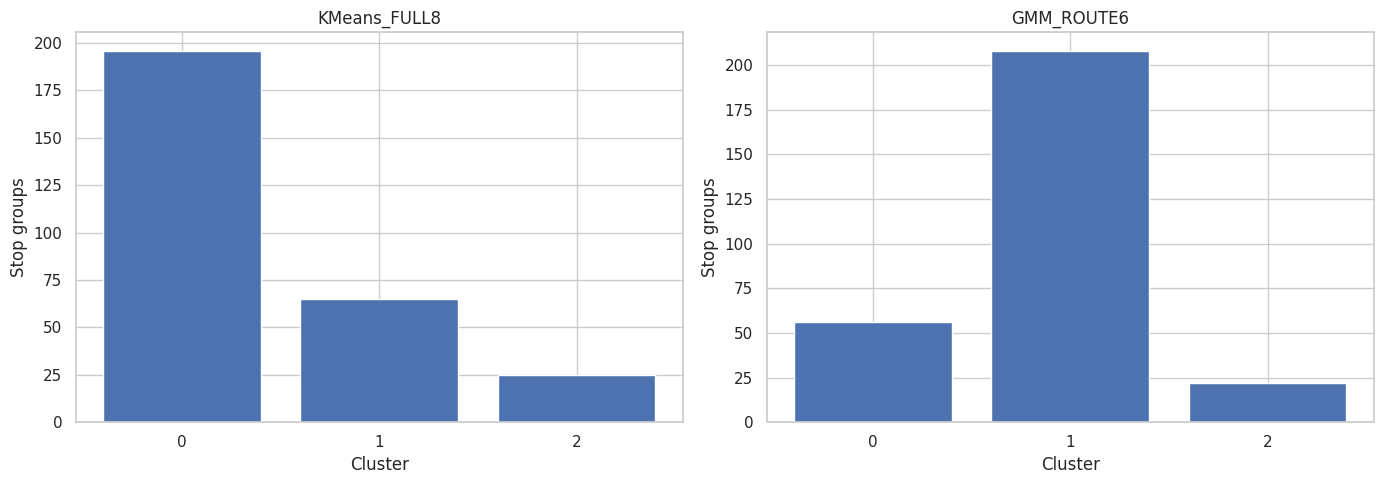

In [3]:
check_cols=CORE+['unique_route_count','demand_cv_hour_profile']
assign=f[['station_name','stop_group_id']+check_cols].copy()
for model,y in labels.items():assign[model]=y
assign.to_csv(OUT/'02_station_assignments_286.csv',index=False,encoding='utf-8-sig')
for model in labels:
    grouped=assign.groupby(model)[check_cols].median()
    grouped.insert(0,'count',assign.groupby(model).size())
    grouped.to_csv(OUT/f'03_cluster_profiles_{model}.csv',encoding='utf-8-sig')
    print('\n',model,'군집별 중앙값');display(grouped.round(3))
    for c in sorted(assign[model].unique()):
        print(f'{model} / Cluster {c}:',len(assign[assign[model]==c]),'개')
        display(assign.loc[assign[model]==c,['station_name','avg_daily_passengers','avg_daily_operations','temporal_mismatch','unique_route_count']].sort_values('avg_daily_passengers',ascending=False).head(10))
cross=pd.crosstab(assign['KMeans_FULL8'],assign['GMM_ROUTE6'])
cross.to_csv(OUT/'04_model_overlap_counts.csv',encoding='utf-8-sig')
display(cross)
fig,axs=plt.subplots(1,2,figsize=(14,5))
for ax,model in zip(axs,labels):
    counts=assign[model].value_counts().sort_index()
    ax.bar(counts.index.astype(str),counts.values)
    ax.set(title=model,xlabel='Cluster',ylabel='Stop groups')
plt.tight_layout();plt.savefig(OUT/'05_cluster_sizes.png',dpi=160);plt.show()


## 3. 월별 정류장군 운영 특성 (월별 관측일 평균)

월간 총 승차량을 단순 비교하면 4·5·6월 관측일 수 차이에 영향을 받으므로 **월별 일평균**을 사용합니다. 정류장별 승객이 매우 적은 경우 상대 증감률을 과장할 수 있어 절대 변화도 같이 표시합니다.

월별 군집 특성: KMeans_FULL8


,KMeans_FULL8,month,station_count,median_daily_passengers,median_daily_operations,median_ppo
0,0,4,196,324.57,429.77,0.77
1,0,5,196,296.08,409.76,0.74
2,0,6,196,310.72,421.97,0.76
3,1,4,65,52.17,131.73,0.36
4,1,5,65,47.19,126.26,0.31
5,1,6,65,52.62,130.14,0.33
6,2,4,25,2058.67,1191.87,1.83
7,2,5,25,1988.48,1133.19,1.87
8,2,6,25,2011.69,1169.52,1.86


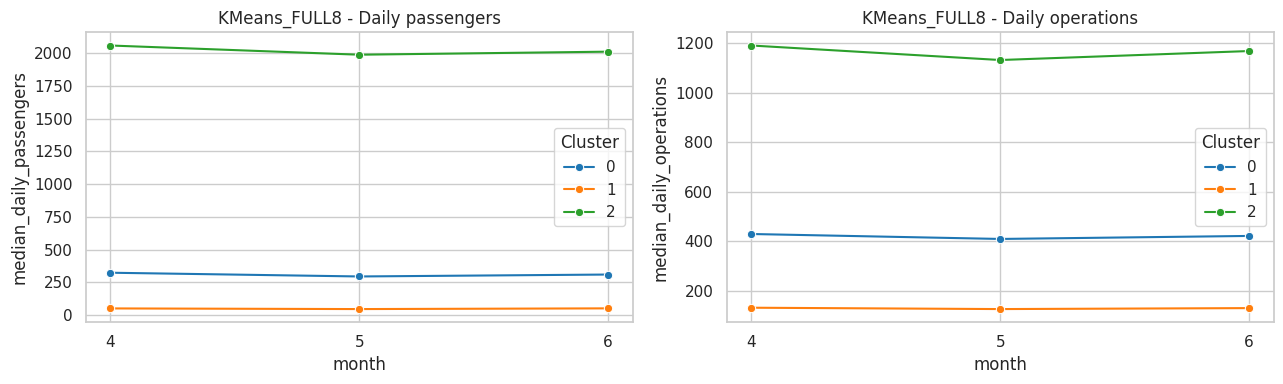

월별 군집 특성: GMM_ROUTE6


,GMM_ROUTE6,month,station_count,median_daily_passengers,median_daily_operations,median_ppo
0,0,4,56,51.62,95.03,0.34
1,0,5,56,46.40,90.61,0.29
2,0,6,56,50.83,93.74,0.31
3,1,4,208,327.10,439.62,0.78
4,1,5,208,297.89,418.31,0.75
5,1,6,208,312.62,430.71,0.77
6,2,4,22,1777.72,1014.72,1.53
7,2,5,22,1642.00,964.08,1.50
8,2,6,22,1676.36,995.66,1.50


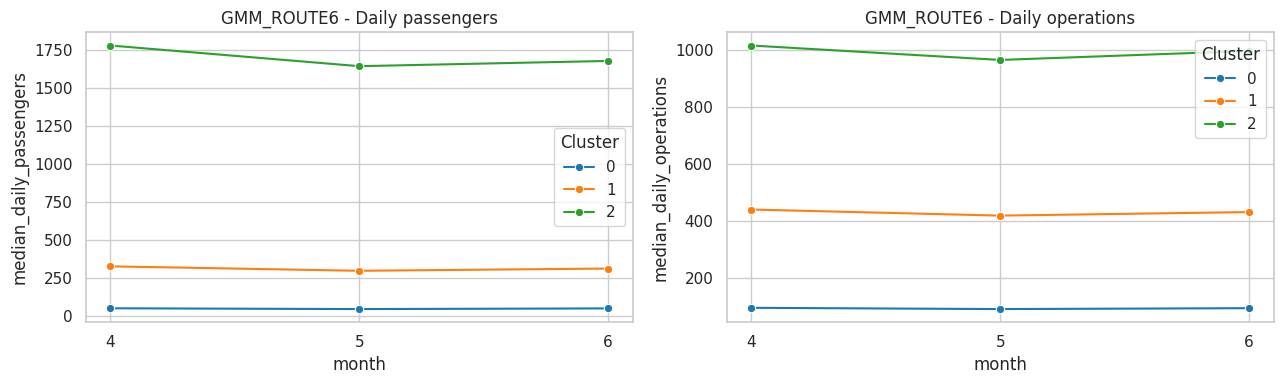

In [4]:
daily=h.groupby(['station_name','date','month'],as_index=False)[['passenger_count','operation_count']].sum()
monthly=daily.groupby(['station_name','month']).agg(
    avg_daily_passengers=('passenger_count','mean'),
    avg_daily_operations=('operation_count','mean'),
    days=('date','nunique'),
).reset_index()
monthly['passengers_per_operation']=monthly.avg_daily_passengers/monthly.avg_daily_operations.replace(0,np.nan)
monthly=monthly.merge(assign[['station_name','KMeans_FULL8','GMM_ROUTE6']],on='station_name',validate='many_to_one')
assert monthly.groupby('station_name').size().eq(3).all()
monthly.to_csv(OUT/'06_monthly_stop_features_286x3.csv',index=False,encoding='utf-8-sig')
for model in labels:
    tab=monthly.groupby([model,'month']).agg(
       station_count=('station_name','nunique'),median_daily_passengers=('avg_daily_passengers','median'),
       median_daily_operations=('avg_daily_operations','median'),median_ppo=('passengers_per_operation','median')
    ).reset_index()
    print('월별 군집 특성:',model);display(tab.round(2))
    tab.to_csv(OUT/f'07_monthly_cluster_profile_{model}.csv',index=False,encoding='utf-8-sig')
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    for ax,col,title in zip(axes,['median_daily_passengers','median_daily_operations'],['Daily passengers','Daily operations']):
        sns.lineplot(data=tab,x='month',y=col,hue=model,marker='o',palette='tab10',ax=ax)
        ax.set_title(f'{model} - {title}');ax.set_xticks([4,5,6]);ax.legend(title='Cluster')
    plt.tight_layout();plt.savefig(OUT/f'08_monthly_profiles_{model}.png',dpi=160);plt.show()


## 4. 월별 순위 재현성 + 변동 큰 정류장 식별

월별 정류장 일평균 승객·운행횟수의 Spearman 순위상관을 비교합니다. **동일 군집 여부가 아니라 공급·수요 규모 순위의 안정성**을 측정합니다.

In [5]:
corr_rows=[]
for col in ['avg_daily_passengers','avg_daily_operations','passengers_per_operation']:
    wide=monthly.pivot(index='station_name',columns='month',values=col)
    for a,c in [(4,5),(4,6),(5,6)]:
        corr_rows.append({'metric':col,'month_a':a,'month_b':c,'spearman':wide[a].corr(wide[c],method='spearman'),'pearson':wide[a].corr(wide[c],method='pearson')})
correlations=pd.DataFrame(corr_rows)
display(correlations.round(4));correlations.to_csv(OUT/'09_month_pair_correlations.csv',index=False,encoding='utf-8-sig')

p=monthly.pivot(index='station_name',columns='month',values='avg_daily_passengers')
variability=pd.DataFrame({'station_name':p.index,'monthly_mean':p.mean(axis=1).values,
    'monthly_min':p.min(axis=1).values,'monthly_max':p.max(axis=1).values})
variability['range_over_mean']=(variability.monthly_max-variability.monthly_min)/variability.monthly_mean.replace(0,np.nan)
variability=variability.sort_values('range_over_mean',ascending=False)
variability.to_csv(OUT/'10_monthly_demand_instability.csv',index=False,encoding='utf-8-sig')
print('월별 승차량 상대 변동 상위 15개 (저수요 정류장 과대 해석 주의)');display(variability.head(15))


,metric,month_a,month_b,spearman,pearson
0,avg_daily_passengers,4,5,0.9992,0.9991
1,avg_daily_passengers,4,6,0.9991,0.9986
2,avg_daily_passengers,5,6,0.9992,0.9988
3,avg_daily_operations,4,5,0.9999,1.0000
4,avg_daily_operations,4,6,0.9999,1.0000
5,avg_daily_operations,5,6,0.9999,1.0000
6,passengers_per_operation,4,5,0.9974,0.9988
7,passengers_per_operation,4,6,0.9955,0.9967
8,passengers_per_operation,5,6,0.9970,0.9972


월별 승차량 상대 변동 상위 15개 (저수요 정류장 과대 해석 주의)


,station_name,monthly_mean,monthly_min,monthly_max,range_over_mean
25,국제이노베이션,0.022605,0.000000,0.034483,1.525424
273,학익풍림아파트,0.447707,0.258065,0.551724,0.655919
175,우진3차아파트,2.305191,1.900000,2.774194,0.379228
281,현광아파트후문앞,0.211284,0.166667,0.241379,0.353612
215,정비단지,108.552169,94.580645,130.800000,0.333659
158,옥련여고입구,147.576035,122.225806,167.433333,0.306334
204,인하대정문,1092.004919,901.862069,1233.733333,0.303910
47,더월드스테이트후문,4.904672,4.100000,5.517241,0.288957
88,삼성빌라(종점),34.145940,28.586207,38.400000,0.287407
236,주안매매단지,10.075924,8.580645,11.413793,0.281180


## 5. 월별 군집 재현성 보조검증 (3개 규모 변수만 사용)

**이 실험은 STEP 2.5 전체 8변수 모델을 월별로 재학습한 결과가 아닙니다.** 전체 기간과 각 월의 `일평균 승차량`, `일평균 운행횟수`, `운행당 승객수` 3변수로 각각 K=3 K-Means를 구성하고 ARI를 확인합니다. PCA 없이 StandardScaler를 사용하며, 같은 286개 정류장군을 유지합니다. 월별로 정의가 확인되지 않은 시간불일치·CV·저공급 비율을 임의 재계산해 혼용하지 않습니다.

In [6]:
month_cols=['avg_daily_passengers','avg_daily_operations','passengers_per_operation']
def monthly_km(dat):
    x=dat[month_cols].replace([np.inf,-np.inf],np.nan)
    z=StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(x))
    return KMeans(n_clusters=3,n_init=20,random_state=42).fit_predict(z)
base_month=f.set_index('station_name').loc[sorted(f.station_name),month_cols].reset_index()
labels_3={'all90':monthly_km(base_month)}
month_model=pd.DataFrame({'station_name':base_month.station_name,'all90':labels_3['all90']})
for m in [4,5,6]:
    s=monthly[monthly.month==m].set_index('station_name').loc[base_month.station_name].reset_index()
    labels_3[str(m)]=monthly_km(s)
    month_model[str(m)]=labels_3[str(m)]
month_model.to_csv(OUT/'11_monthly_3feature_clustering.csv',index=False,encoding='utf-8-sig')
rows=[]
for a,other in [('all90','4'),('all90','5'),('all90','6'),('4','5'),('4','6'),('5','6')]:
    rows.append({'model_a':a,'model_b':other,'ari':adjusted_rand_score(labels_3[a],labels_3[other])})
ari=pd.DataFrame(rows);display(ari);ari.to_csv(OUT/'12_monthly_3feature_ARI.csv',index=False,encoding='utf-8-sig')
print('주의: 위 ARI는 3변수 월별 보조검증 지표이며, 8변수 전체 모델의 월별 ARI로 인용하면 안 됩니다.')


,model_a,model_b,ari
0,all90,4,1.000000
1,all90,5,0.985387
2,all90,6,0.985387
3,4,5,0.985387
4,4,6,0.985387
5,5,6,1.000000


주의: 위 ARI는 3변수 월별 보조검증 지표이며, 8변수 전체 모델의 월별 ARI로 인용하면 안 됩니다.


## 6. 군집별 시간대 수요·공급 패턴

모델 전체 기간 군집을 고정하고 각 유형의 시간대별 수요와 운행 분포를 비교합니다. **수요·공급 비중 차이만으로 실제 대기시간이나 미충족 수요는 추정하지 않습니다.**

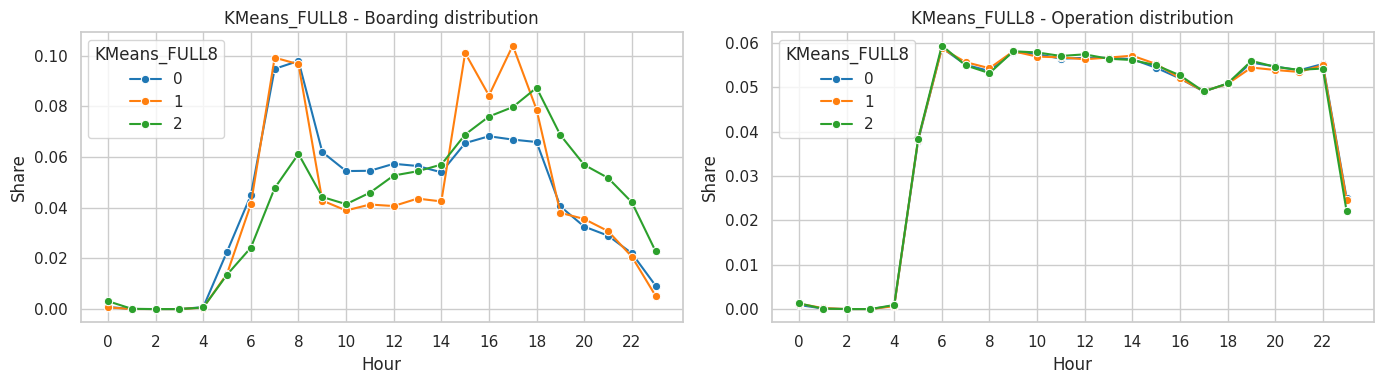

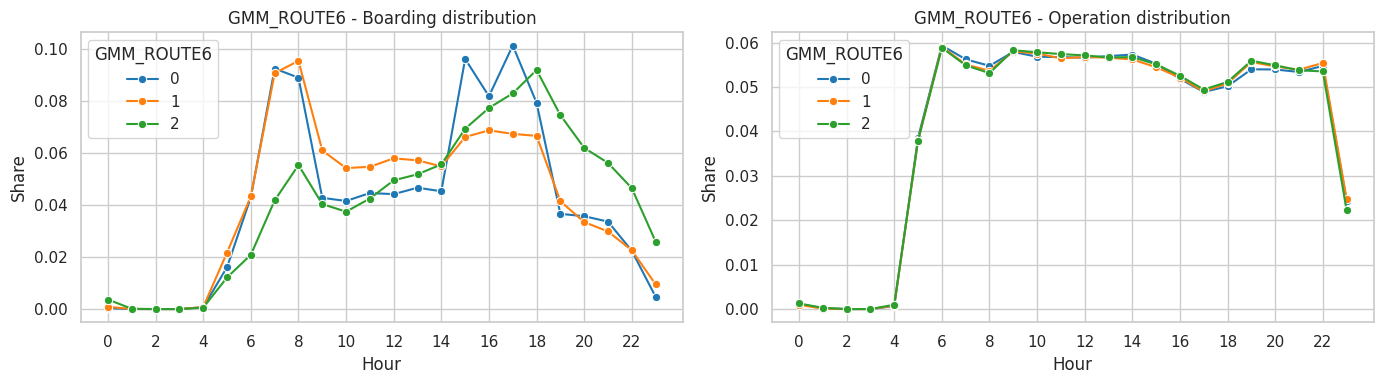

In [7]:
for model in labels:
    pattern=(h[['station_name','hour','passenger_count','operation_count']]
      .merge(assign[['station_name',model]],on='station_name',validate='many_to_one')
      .groupby([model,'hour'],as_index=False)[['passenger_count','operation_count']].sum())
    for col in ['passenger_count','operation_count']:
        pattern[f'{col}_share']=pattern[col]/pattern.groupby(model)[col].transform('sum').replace(0,np.nan)
    pattern.to_csv(OUT/f'13_hourly_cluster_patterns_{model}.csv',index=False,encoding='utf-8-sig')
    fig,axs=plt.subplots(1,2,figsize=(14,4))
    for ax,col,title in zip(axs,['passenger_count_share','operation_count_share'],['Boarding distribution','Operation distribution']):
        sns.lineplot(data=pattern,x='hour',y=col,hue=model,ax=ax,marker='o',palette='tab10')
        ax.set(title=f'{model} - {title}',xlabel='Hour',ylabel='Share');ax.set_xticks(range(0,24,2))
    plt.tight_layout();plt.savefig(OUT/f'14_hourly_patterns_{model}.png',dpi=160);plt.show()


## 7. 보고서 작성용 점검사항 및 ZIP 다운로드

- K-Means와 GMM의 군집 번호 자체는 서로 대응하지 않습니다. `04_model_overlap_counts.csv`와 ARI를 함께 활용합니다.
- 노선 수 결측 2개는 모델 재현을 위해 **전체기간 중앙값으로 대체**합니다. 원자료 값을 고친 것은 아닙니다.
- 4~6월 노선 수는 6/30 기준 단면 자료이므로 월별 노선 변동까지 평가한 것은 아닙니다.
- STEP 3의 월별 ARI는 3개 규모 변수 기반 **보조 검증**입니다. 시간적 불일치의 월별 계산 기준을 확보하면 동일 8변수 월별 재학습으로 확장할 수 있습니다.
- STEP 3은 후보 정류장군의 *유형 해석*이지 I-MOD 공급 부족이나 도입 우선순위를 확정하는 단계가 아닙니다.

In [8]:
zip_path=Path('Michuhol_IMOD_STEP3_Interpretation_Results.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.glob('*')):z.write(p,arcname=p.name)
print('결과 파일:',zip_path,'/ 산출물 개수:',len(list(OUT.glob('*'))))
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError: pass


결과 파일: Michuhol_IMOD_STEP3_Interpretation_Results.zip / 산출물 개수: 19


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>